# 교양교과목록 학년도별 트렌드 및 교과 편성 분석

이 노트북은 `[수정본]교양교과목록_최종.xlsx` 파일을 활용하여
학년도별 교양 교과 편성 현황과 텍스트 기반 트렌드를 분석하기 위한 예시 코드입니다.

사용자 환경에 맞게 **엑셀 파일 경로만 수정**하면 바로 실행할 수 있습니다.

In [3]:
!pip install pandas matplotlib
!pip install scikit-learn
!pip install wordcloud
!pip install openpyxl
!pip install notebook


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# ==== [한글 폰트 설정 - Windows] ====
from matplotlib import font_manager, rc
font_path = "C:/Windows/Fonts/malgun.ttf"
font = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font)

plt.rcParams['axes.unicode_minus'] = False
# =====================================


NameError: name 'plt' is not defined

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

# 주피터에서 그래프 바로 보기
%matplotlib inline

## 1. 데이터 로딩

- 아래 경로를 **사용자 PC에 저장된 실제 파일 경로**로 수정해서 사용하세요.
- 예시: `r"C:/Users/username/Desktop/[수정본]교양교과목록_최종.xlsx"`

In [ ]:
# TODO: 사용자 환경에 맞게 경로를 수정하세요.
excel_path = r"data/[수정본]교양교과목록_최종.xlsx"  # 예시: 로컬에서는 C:/... 로 변경

df = pd.read_excel(excel_path)

print(df.head())
print(df.columns)

    학년도  학기 / 보류      교과목명                                               교과설명  \
0  2025        1   자연재해의이해  자연재해와 관련하여 엘리뇨, 지구온난화, 태풍, 홍수, 가뭄, 수질오염, 산사태, ...   
1  2025        1    사회봉사활동  현장에 직접 나가 봉사활동을 실시하며, 활동영역으로는 캠퍼스, 농어촌, 공공기관, ...   
2  2025        1  세계의민족과문화  이 강좌는 문화인류학 연구 성과에 기반하여 각 민족과 그들의 문화를 이해하는 것을 ...   
3  2025        1      교양음악  음악에 대한 기초적인 지식을 배우며 음악감상 등을 통해 음악에 대해 쉽게 접근을 할...   
4  2025        1    자동차와생활  현대적인 생활에 있어서 자동차는 누구나 쉽게 보유하고 운전하게 됨으로서 이제는 자동...   

  이수구분  수강기준학년  수강기준학기  
0   교선       0       0  
1   교필       0       0  
2   교선       0       0  
3   교선       0       0  
4   교선       0       0  
Index(['학년도', '학기 / 보류', '교과목명', '교과설명', '이수구분', '수강기준학년', '수강기준학기'], dtype='object')


## 2. 기본 전처리

- `학년도`를 정수형으로 변환
- `교과설명` 결측치는 빈 문자열로 대체

In [ ]:
df['학년도'] = df['학년도'].astype(int)
df['교과설명'] = df['교과설명'].fillna("")

df[['학년도', '이수구분', '교과목명']].head()

,학년도,이수구분,교과목명
0,2025,교선,자연재해의이해
1,2025,교필,사회봉사활동
2,2025,교선,세계의민족과문화
3,2025,교선,교양음악
4,2025,교선,자동차와생활


## 3. 학년도별 개설 과목 수 변화

- 각 학년도별로 교양 교과목 개설 수를 집계합니다.
- 막대그래프로 연도별 변화 추이를 시각화합니다.

학년도
2022     44
2023     34
2024     85
2025    165
Name: 교과목명, dtype: int64

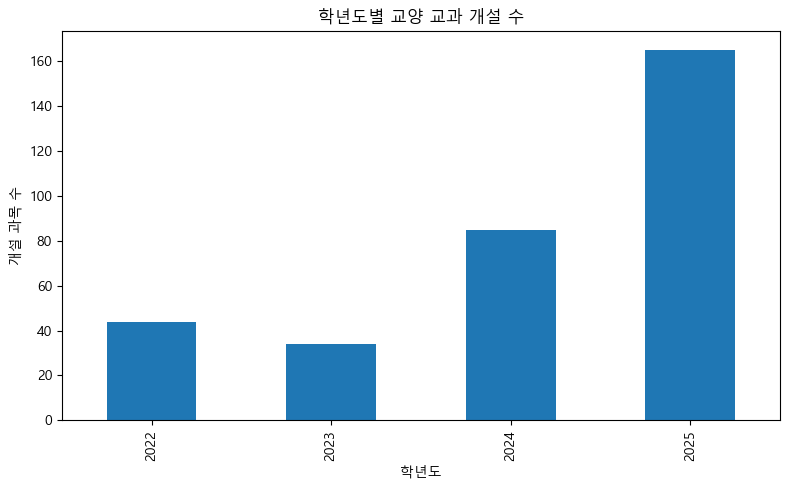

In [ ]:
year_count = df.groupby('학년도')['교과목명'].count()
display(year_count)

plt.figure(figsize=(8, 5))
year_count.plot(kind='bar')
plt.title('학년도별 교양 교과 개설 수')
plt.xlabel('학년도')
plt.ylabel('개설 과목 수')
plt.tight_layout()
plt.show()

## 4. 학년도별 이수구분 비율 분석

- 학년도 x 이수구분(교필/교선/자선/채플/전선 등)으로 피벗테이블 생성
- 각 연도별 전체 과목 수 대비 비율을 계산
- 누적 막대그래프로 시각화

이수구분,교선,교필,자선,전선,채플
학년도,,,,,
2022,28,12,3,1,0
2023,14,19,1,0,0
2024,43,31,10,1,0
2025,87,63,14,0,1


이수구분,교선,교필,자선,전선,채플
학년도,,,,,
2022,0.636364,0.272727,0.068182,0.022727,0.000000
2023,0.411765,0.558824,0.029412,0.000000,0.000000
2024,0.505882,0.364706,0.117647,0.011765,0.000000
2025,0.527273,0.381818,0.084848,0.000000,0.006061


<Figure size 1000x600 with 0 Axes>

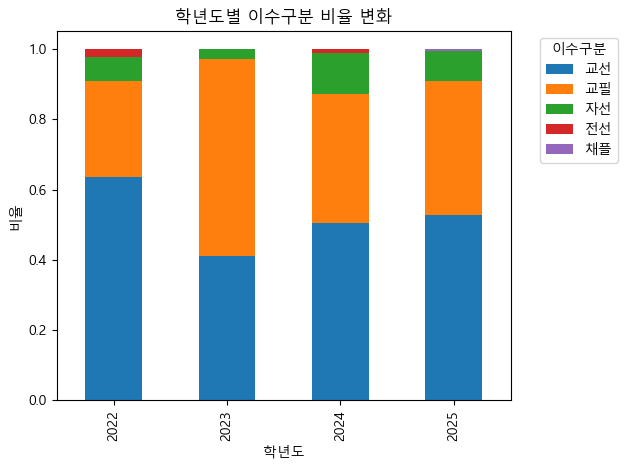

In [ ]:
year_type = df.groupby(['학년도', '이수구분']).size().unstack(fill_value=0)
display(year_type)

# 비율 계산
year_type_ratio = year_type.div(year_type.sum(axis=1), axis=0)
display(year_type_ratio)

plt.figure(figsize=(10, 6))
year_type_ratio.plot(kind='bar', stacked=True)
plt.title('학년도별 이수구분 비율 변화')
plt.xlabel('학년도')
plt.ylabel('비율')
plt.legend(title='이수구분', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 5. 학년도별 교과설명 텍스트 트렌드 (TF-IDF 기반)

- 각 학년도별 `교과설명` 텍스트를 모아 TF-IDF를 계산
- 연도별 상위 키워드를 추출하여 교육 트렌드를 파악합니다.

In [ ]:
def top_keywords_by_year(df, year, top=20):
    # 결측값 제거 (핵심)
    df['교과설명'] = df['교과설명'].fillna("")

    texts = df[df['학년도'] == year]['교과설명'].tolist()
    if not texts:
        return pd.Series(dtype=float)

    stop_words = ['있다', '위한', '및', '하는', '통해']
    vectorizer = TfidfVectorizer(max_features=2000, stop_words=stop_words)

    try:
        X = vectorizer.fit_transform(texts)
    except ValueError as e:
        print(f"{year}년 오류:", e)
        return pd.Series(dtype=float)

    scores = X.sum(axis=0).A1
    keywords = pd.Series(scores, index=vectorizer.get_feature_names_out())
    return keywords.sort_values(ascending=False).head(top)


# 예시: 각 학년도 상위 20개 키워드 출력
for year in sorted(df['학년도'].unique()):
    print(f"\n=== {year}년 상위 키워드 ===")
    print(top_keywords_by_year(df, year, top=20))


=== 2022년 상위 키워드 ===
한국어       2.135959
능력을       1.309325
있는        1.282131
대한        1.240468
학생들이      1.176042
목적으로      1.071841
철학과삶이란    1.000000
수행할       0.980865
이러한       0.980865
합니다       0.980865
배양함을      0.980865
외국인       0.980865
능력        0.973083
있도록       0.965259
창업        0.938914
이해를       0.915930
글쓰기를      0.863778
학습을       0.853160
심화        0.826958
과목은       0.826039
dtype: float64

=== 2023년 상위 키워드 ===
있는      1.415345
한국어     1.213485
다양한     1.098183
것을      1.022482
한다      1.022070
학생들이    0.956268
영어      0.897311
목표로     0.817054
이해하고    0.755684
통하여     0.714750
바탕으로    0.708724
있도록     0.707326
능력을     0.695215
수업은     0.692688
과목은     0.691452
영어를     0.637585
학습하고    0.626046
대하여     0.622648
필요한     0.621705
외국인     0.584529
dtype: float64

=== 2024년 상위 키워드 ===
등을      1.939984
대한      1.838364
다양한     1.737883
학습한다    1.551043
대해      1.483801
대하여     1.462748
현대      1.450657
이해      1.390449
한다      1.345082
이를      1.263018
있는      1.2248

## 6. 학년도별 교과설명 워드클라우드

- 각 학년도별로 교과설명을 모두 합쳐 워드클라우드를 생성합니다.
- 시각적으로 해당 연도의 핵심 키워드를 파악할 수 있습니다.

In [ ]:
for year in sorted(df['학년도'].unique()):
    text = " ".join(df[df['학년도'] == year]['교과설명'])
    if not text.strip():
        continue

    wc = WordCloud(width=800, height=400, background_color='white').generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'{year}년도 교과설명 워드클라우드')
    plt.show()

NameError: name 'df' is not defined

## 7. 연도별 신규/폐지 교과 탐지

- 전년도에 없고 해당 연도에만 등장하는 과목: **신규 교과**
- 전년도에는 있었는데 해당 연도에 사라진 과목: **폐지 교과**

In [ ]:
years = sorted(df['학년도'].unique())
new_courses = {}
deleted_courses = {}

for i in range(1, len(years)):
    prev_year = years[i-1]
    curr_year = years[i]

    prev = set(df[df['학년도'] == prev_year]['교과목명'])
    curr = set(df[df['학년도'] == curr_year]['교과목명'])

    new_courses[curr_year] = sorted(list(curr - prev))
    deleted_courses[curr_year] = sorted(list(prev - curr))

print("\n=== 연도별 신규 교과 ===")
for y, lst in new_courses.items():
    print(f"{y}년 신규 교과 수: {len(lst)}")
    print(lst[:20])  # 너무 길면 앞 20개만

print("\n=== 연도별 폐지 교과 ===")
for y, lst in deleted_courses.items():
    print(f"{y}년 기준 폐지 교과 수: {len(lst)}")
    print(lst[:20])

NameError: name 'df' is not defined